In [ ]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

devapriyadas_mars_100_data_path = kagglehub.dataset_download('devapriyadas/mars-100-data')
devapriyadas_test_sets_path = kagglehub.dataset_download('devapriyadas/test-sets')

print('Data source import complete.')


In [ ]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

IMG_SIZE = 256
BATCH_SIZE = 4
EPOCHS = 100
LR = 1e-3
NUM_CLASSES = 2
EXTS = (".png", ".jpg", ".jpeg")


Using device: cuda


In [ ]:
from torch.utils.data import Dataset
import os
import numpy as np
from PIL import Image
import torch
from torchvision import transforms

class SegDataset(Dataset):
    def __init__(self, img_dir, mask_dir, threshold=90, invert_mask=False):
        self.imgs = sorted([
            os.path.join(img_dir, f)
            for f in os.listdir(img_dir)
            if f.endswith(EXTS)
        ])
        self.masks = sorted([
            os.path.join(mask_dir, f)
            for f in os.listdir(mask_dir)
            if f.endswith(EXTS)
        ])

        assert len(self.imgs) == len(self.masks), "Image–mask mismatch"
        assert len(self.imgs) > 0, f"No images found in {img_dir}"

        self.threshold = threshold
        self.invert_mask = invert_mask

        self.img_tf = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, i):
        # Image
        img = self.img_tf(Image.open(self.imgs[i]).convert("RGB"))

        # Mask
        mask = Image.open(self.masks[i]).convert("L")
        mask = mask.resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)
        mask = np.array(mask)

        if self.invert_mask:
            mask = 255 - mask

        mask = (mask > self.threshold).astype(np.int64)
        mask = torch.from_numpy(mask)

        return img, mask

In [ ]:
train_dataset = SegDataset(
    img_dir="/kaggle/input/mars-100-data/Mars_100(Data)/train_images",
    mask_dir="/kaggle/input/mars-100-data/Mars_100(Data)/train_masks",
    threshold=90,
    invert_mask=False   # try True if rough areas are dark
)

val_dataset = SegDataset(
    img_dir="/kaggle/input/mars-100-data/Mars_100(Data)/val_images",
    mask_dir="/kaggle/input/mars-100-data/Mars_100(Data)/val_masks",
    threshold=90,
    invert_mask=False
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
print("Train samples:", len(train_dataset))
print("Val samples:", len(val_dataset))

Train samples: 110
Val samples: 60


In [ ]:
# Inspect one batch
x, y = next(iter(train_loader))
print("Mask dtype:", y.dtype)
print("Mask min:", y.min().item())
print("Mask max:", y.max().item())
print("Unique values:", torch.unique(y))


Mask dtype: torch.int64
Mask min: 0
Mask max: 1
Unique values: tensor([0, 1])


In [ ]:
class SignSTE(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        return x.sign()

    @staticmethod
    def backward(ctx, grad):
        return grad.clone()

def binarize(x):
    return SignSTE.apply(x)


In [ ]:
class BinaryConv(nn.Conv2d):
    def forward(self, x):
        w_bin = binarize(self.weight)
        return F.conv2d(x, w_bin, self.bias, self.stride,
                        self.padding, self.dilation, self.groups)


In [ ]:
class BinaryUNet(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        # =======================
        # Encoder
        # =======================
        self.e1 = nn.Conv2d(3, 32, 3, padding=1)
        self.e2 = nn.Conv2d(32, 64, 3, padding=1)

        self.e3 = BinaryConv(64, 128, 3, padding=1)
        self.e4 = BinaryConv(128, 256, 3, padding=1)

        # =======================
        # Decoder (concat-based)
        # =======================
        self.d3 = nn.Conv2d(256 + 128, 128, 3, padding=1)
        self.d2 = nn.Conv2d(128 + 64, 64, 3, padding=1)
        self.d1 = nn.Conv2d(64 + 32, 32, 3, padding=1)

        # =======================
        # Output
        # =======================
        self.out = nn.Conv2d(32, num_classes, 1)

    def forward(self, x):
        # -------- Encoder --------
        e1 = F.relu(self.e1(x))                        # [B,32,256,256]
        e2 = F.relu(self.e2(F.max_pool2d(e1, 2)))      # [B,64,128,128]

        e3 = F.relu(self.e3(F.max_pool2d(e2, 2)))      # [B,128,64,64]
        # removed tanh+binarize

        e4 = F.relu(self.e4(F.max_pool2d(e3, 2)))      # [B,256,32,32]
        # removed tanh+binarize

        # -------- Decoder --------
        d3 = F.interpolate(e4, scale_factor=2, mode="nearest")
        d3 = torch.cat([d3, e3], dim=1)
        d3 = F.relu(self.d3(d3))

        d2 = F.interpolate(d3, scale_factor=2, mode="nearest")
        d2 = torch.cat([d2, e2], dim=1)
        d2 = F.relu(self.d2(d2))

        d1 = F.interpolate(d2, scale_factor=2, mode="nearest")
        d1 = torch.cat([d1, e1], dim=1)
        d1 = F.relu(self.d1(d1))

        return self.out(d1)


In [ ]:
def compute_iou_dice(pred, target, num_classes=2, eps=1e-6):
    """
    pred: [B, H, W]  (class indices)
    target: [B, H, W]
    """
    iou_per_class = []
    dice_per_class = []

    for cls in range(num_classes):
        pred_c = (pred == cls)
        target_c = (target == cls)

        intersection = (pred_c & target_c).sum().float()
        union = (pred_c | target_c).sum().float()

        iou = (intersection + eps) / (union + eps)
        dice = (2 * intersection + eps) / (
            pred_c.sum().float() + target_c.sum().float() + eps
        )

        iou_per_class.append(iou.item())
        dice_per_class.append(dice.item())

    return iou_per_class, dice_per_class


In [ ]:
from collections import Counter

counter = Counter()
for _, y in train_loader:
    counter.update(y.view(-1).tolist())

print(counter)


Counter({1: 5273065, 0: 1935895})


In [ ]:
counts = torch.tensor([131706, 7077254], dtype=torch.float)
weights = counts.sum() / (2 * counts)
weights = weights.to(device)

criterion = nn.CrossEntropyLoss(weight=weights)
print("Class weights:", weights)


Class weights: tensor([27.3676,  0.5093], device='cuda:0')


In [ ]:
train_loss_history = []
val_loss_history = []

train_mean_iou_history = []
val_mean_iou_history = []


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from tqdm import tqdm

# =====================
# CONFIG
# =====================
NUM_CLASSES = 2
LR = 1e-4
EPOCHS = 100
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =====================
# MODEL
# =====================
model = BinaryUNet().to(device)
optimizer = optim.Adam(model.parameters(), lr=LR)

# =====================
# LOSS FUNCTIONS
# =====================
# Strong class weighting (boost rough terrain = class 0)
weights = torch.tensor([50.0, 1.0], device=device)
criterion_ce = nn.CrossEntropyLoss(weight=weights)

def dice_loss(logits, targets, eps=1e-6):
    probs = torch.softmax(logits, dim=1)
    targets_onehot = torch.nn.functional.one_hot(targets, num_classes=NUM_CLASSES)
    targets_onehot = targets_onehot.permute(0, 3, 1, 2).float()

    intersection = (probs * targets_onehot).sum(dim=(2, 3))
    union = probs.sum(dim=(2, 3)) + targets_onehot.sum(dim=(2, 3))

    dice = (2 * intersection + eps) / (union + eps)
    return 1 - dice.mean()

# =====================
# METRIC STORAGE
# =====================
train_loss_history = []
val_loss_history = []
train_mean_iou_history = []
val_mean_iou_history = []

# =====================
# BEST MODEL TRACKING
# =====================
best_val_iou_class0 = -1.0
best_model_path = "best_model_class0_iou.pth"

# =====================
# TRAINING LOOP
# =====================
for epoch in range(EPOCHS):

    # --------------------
    # TRAINING
    # --------------------
    model.train()
    train_loss_total = 0.0
    train_iou = np.zeros(NUM_CLASSES)
    train_dice = np.zeros(NUM_CLASSES)
    train_batches = 0

    for x, y in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]"):
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        logits = model(x)

        loss = criterion_ce(logits, y) + 1.5 * dice_loss(logits, y)
        loss.backward()
        optimizer.step()

        train_loss_total += loss.item()
        train_batches += 1

        preds = torch.argmax(logits, dim=1)

        for c in range(NUM_CLASSES):
            pred_c = (preds == c).float()
            target_c = (y == c).float()
            inter = (pred_c * target_c).sum().item()
            union = pred_c.sum().item() + target_c.sum().item()

            if union > 0:
                dice = 2 * inter / union
                iou = inter / (union - inter + 1e-6)
            else:
                dice = 0.0
                iou = 0.0

            train_iou[c] += iou
            train_dice[c] += dice

    train_loss = train_loss_total / train_batches
    train_iou /= train_batches
    train_dice /= train_batches
    train_mean_iou = np.mean(train_iou)

    # --------------------
    # VALIDATION
    # --------------------
    model.eval()
    val_loss_total = 0.0
    val_iou = np.zeros(NUM_CLASSES)
    val_dice = np.zeros(NUM_CLASSES)
    val_batches = 0

    with torch.no_grad():
        for x, y in tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]", leave=False):
            x, y = x.to(device), y.to(device)
            logits = model(x)

            loss = criterion_ce(logits, y) + 1.5 * dice_loss(logits, y)
            val_loss_total += loss.item()
            val_batches += 1

            preds = torch.argmax(logits, dim=1)

            for c in range(NUM_CLASSES):
                pred_c = (preds == c).float()
                target_c = (y == c).float()
                inter = (pred_c * target_c).sum().item()
                union = pred_c.sum().item() + target_c.sum().item()

                if union > 0:
                    dice = 2 * inter / union
                    iou = inter / (union - inter + 1e-6)
                else:
                    dice = 0.0
                    iou = 0.0

                val_iou[c] += iou
                val_dice[c] += dice

    val_loss = val_loss_total / val_batches
    val_iou /= val_batches
    val_dice /= val_batches
    val_mean_iou = np.mean(val_iou)

    # --------------------
    # SAVE HISTORY
    # --------------------
    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)
    train_mean_iou_history.append(train_mean_iou)
    val_mean_iou_history.append(val_mean_iou)

    # --------------------
    # SAVE BEST MODEL (Class 0 IoU)
    # --------------------
    if val_iou[0] > best_val_iou_class0:
        best_val_iou_class0 = val_iou[0]
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_iou_class0": best_val_iou_class0
        }, best_model_path)

        print(f"  ✅ Best model saved! (Class 0 IoU = {best_val_iou_class0:.4f})")

    # --------------------
    # PRINT METRICS
    # --------------------
    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    print(f"  Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    print("  Train Metrics:")
    for c in range(NUM_CLASSES):
        print(f"    Class {c} | IoU: {train_iou[c]:.4f} | Dice: {train_dice[c]:.4f}")
    print(f"    Mean IoU: {train_mean_iou:.4f}")

    print("  Val Metrics:")
    for c in range(NUM_CLASSES):
        print(f"    Class {c} | IoU: {val_iou[c]:.4f} | Dice: {val_dice[c]:.4f}")
    print(f"    Mean IoU: {val_mean_iou:.4f}")

# =====================
# FINAL SUMMARY
# =====================
print("\n🏆 Training Complete")
print(f"Best Class 0 IoU: {best_val_iou_class0:.4f}")
print(f"Best model saved at: {best_model_path}")


Epoch 1/100 [Train]: 100%|██████████| 28/28 [00:02<00:00, 10.67it/s]


  ✅ Best model saved! (Class 0 IoU = 0.3535)

Epoch [1/100]
  Train Loss: 1.2118 | Val Loss: 0.9677
  Train Metrics:
    Class 0 | IoU: 0.2785 | Dice: 0.4340
    Class 1 | IoU: 0.0533 | Dice: 0.0801
    Mean IoU: 0.1659
  Val Metrics:
    Class 0 | IoU: 0.3535 | Dice: 0.5217
    Class 1 | IoU: 0.4254 | Dice: 0.5950
    Mean IoU: 0.3895


Epoch 2/100 [Train]: 100%|██████████| 28/28 [00:01<00:00, 17.94it/s]


  ✅ Best model saved! (Class 0 IoU = 0.5381)

Epoch [2/100]
  Train Loss: 0.9273 | Val Loss: 0.8094
  Train Metrics:
    Class 0 | IoU: 0.3952 | Dice: 0.5632
    Class 1 | IoU: 0.4608 | Dice: 0.5937
    Mean IoU: 0.4280
  Val Metrics:
    Class 0 | IoU: 0.5381 | Dice: 0.6993
    Class 1 | IoU: 0.7823 | Dice: 0.8776
    Mean IoU: 0.6602


Epoch 3/100 [Train]: 100%|██████████| 28/28 [00:01<00:00, 18.02it/s]


...


Epoch [98/100]
  Train Loss: 0.2751 | Val Loss: 0.7051
  Train Metrics:
    Class 0 | IoU: 0.7271 | Dice: 0.8414
    Class 1 | IoU: 0.8656 | Dice: 0.9277
    Mean IoU: 0.7963
  Val Metrics:
    Class 0 | IoU: 0.7130 | Dice: 0.8324
    Class 1 | IoU: 0.8864 | Dice: 0.9397
    Mean IoU: 0.7997


Epoch 99/100 [Train]: 100%|██████████| 28/28 [00:01<00:00, 16.62it/s]



Epoch [99/100]
  Train Loss: 0.2973 | Val Loss: 0.6364
  Train Metrics:
    Class 0 | IoU: 0.7096 | Dice: 0.8287
    Class 1 | IoU: 0.8516 | Dice: 0.9191
    Mean IoU: 0.7806
  Val Metrics:
    Class 0 | IoU: 0.7060 | Dice: 0.8275
    Class 1 | IoU: 0.8807 | Dice: 0.9365
    Mean IoU: 0.7934


Epoch 100/100 [Train]: 100%|██████████| 28/28 [00:01<00:00, 17.01it/s]
                                                                    


Epoch [100/100]
  Train Loss: 0.2720 | Val Loss: 0.9276
  Train Metrics:
    Class 0 | IoU: 0.7271 | Dice: 0.8415
    Class 1 | IoU: 0.8639 | Dice: 0.9266
    Mean IoU: 0.7955
  Val Metrics:
    Class 0 | IoU: 0.7021 | Dice: 0.8249
    Class 1 | IoU: 0.8884 | Dice: 0.9408
    Mean IoU: 0.7952

🏆 Training Complete
Best Class 0 IoU: 0.7286
Best model saved at: best_model_class0_iou.pth


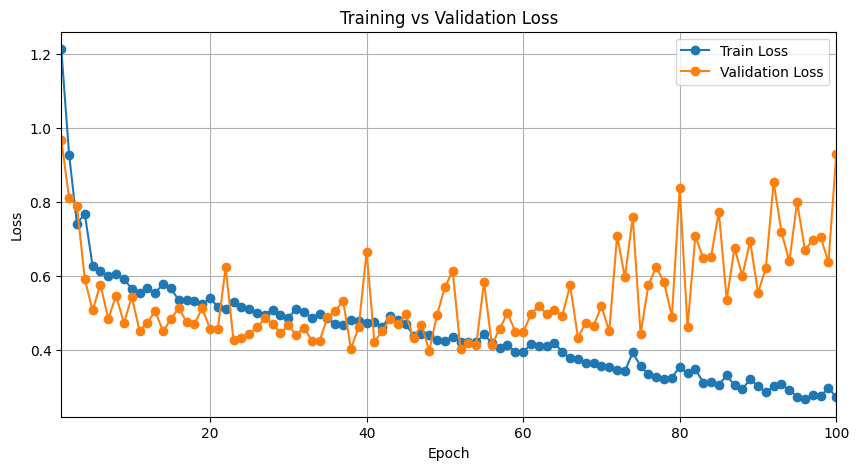

In [ ]:
import matplotlib.pyplot as plt

epochs = list(range(1, len(train_loss_history) + 1))

plt.figure(figsize=(10,5))
plt.plot(epochs, train_loss_history, marker='o', label='Train Loss')
plt.plot(epochs, val_loss_history, marker='o', label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.xlim(1, len(epochs))   # 👈 force full epoch range
plt.legend()
plt.grid(True)
plt.show()




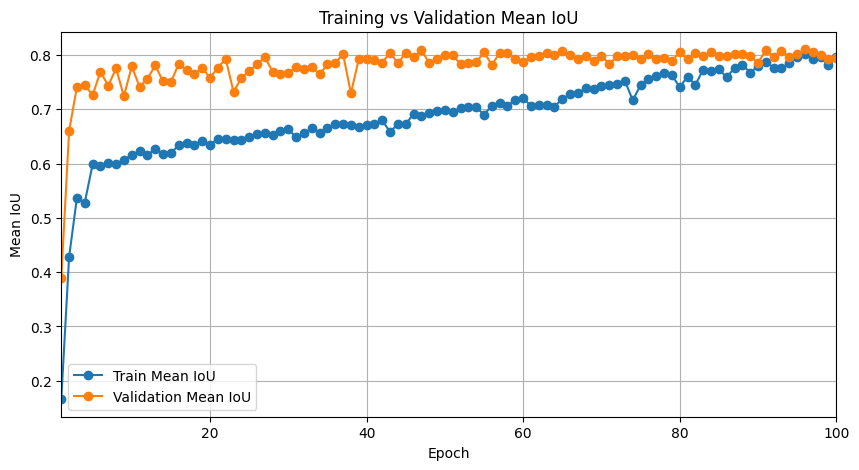

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(epochs, train_mean_iou_history, marker='o', label='Train Mean IoU')
plt.plot(epochs, val_mean_iou_history, marker='o', label='Validation Mean IoU')
plt.xlabel("Epoch")
plt.ylabel("Mean IoU")
plt.title("Training vs Validation Mean IoU")
plt.xlim(1, len(epochs))
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Number of trainable parameters: {num_params:,}")

# Approximate memory size (float32 weights)
model_size_mb = num_params * 4 / (1024 ** 2)
print(f"Approximate model size (float32): {model_size_mb:.2f} MB")

Number of trainable parameters: 969,314
Approximate model size (float32): 3.70 MB


In [ ]:
import torch
import numpy as np

model.eval()
dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device)

# Warmup
with torch.no_grad():
    for _ in range(30):
        _ = model(dummy_input)

torch.cuda.synchronize()

starter = torch.cuda.Event(enable_timing=True)
ender = torch.cuda.Event(enable_timing=True)

times = []
with torch.no_grad():
    for _ in range(300):
        starter.record()
        _ = model(dummy_input)
        ender.record()
        torch.cuda.synchronize()
        times.append(starter.elapsed_time(ender))  # milliseconds

avg_latency_ms = np.mean(times)
fps = 1000.0 / avg_latency_ms

print(f"Average latency (batch=1): {avg_latency_ms:.2f} ms/image")
print(f"FPS (batch=1): {fps:.2f}")


Average latency (batch=1): 3.67 ms/image
FPS (batch=1): 272.27


In [ ]:
def evaluate_metrics(model, loader, device, num_classes=NUM_CLASSES, eps=1e-6):
    model.eval()
    tp = torch.zeros(num_classes, device=device)
    fp = torch.zeros(num_classes, device=device)
    fn = torch.zeros(num_classes, device=device)

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            preds = torch.argmax(logits, dim=1)  # [B, H, W]

            for c in range(num_classes):
                p_c = (preds == c)
                t_c = (y == c)
                tp[c] += (p_c & t_c).sum()
                fp[c] += (p_c & ~t_c).sum()
                fn[c] += (~p_c & t_c).sum()

    ious, dices, precs, recs = [], [], [], []
    print("\nValidation Metrics (global over entire val set):")
    for c in range(num_classes):
        union = tp[c] + fp[c] + fn[c]
        iou = tp[c] / (union + eps)
        dice = 2 * tp[c] / (2 * tp[c] + fp[c] + fn[c] + eps)
        prec = tp[c] / (tp[c] + fp[c] + eps)
        rec = tp[c] / (tp[c] + fn[c] + eps)

        ious.append(iou.item())
        dices.append(dice.item())
        precs.append(prec.item())
        recs.append(rec.item())

        print(f"  Class {c} (0=rough, 1=smooth): IoU {iou:.4f} | Dice {dice:.4f} | Prec {prec:.4f} | Rec {rec:.4f}")

    mean_iou = sum(ious) / num_classes
    mean_dice = sum(dices) / num_classes
    mean_prec = sum(precs) / num_classes
    mean_rec = sum(recs) / num_classes

    print(f"  Mean (macro avg): IoU {mean_iou:.4f} | Dice {mean_dice:.4f} | Prec {mean_prec:.4f} | Rec {mean_rec:.4f}")

    return mean_iou, mean_dice, mean_prec, mean_rec

# Call after training
evaluate_metrics(model, val_loader, device)


Validation Metrics (global over entire val set):
  Class 0 (0=rough, 1=smooth): IoU 0.7015 | Dice 0.8246 | Prec 0.8286 | Rec 0.8206
  Class 1 (0=rough, 1=smooth): IoU 0.8887 | Dice 0.9411 | Prec 0.9396 | Rec 0.9426
  Mean (macro avg): IoU 0.7951 | Dice 0.8828 | Prec 0.8841 | Rec 0.8816


(0.7951285243034363, 0.8828359544277191, 0.8840800523757935, 0.881613701581955)

In [ ]:
# =========================
# LOAD BEST MODEL (PyTorch 2.6 FIX)
# =========================
model = BinaryUNet().to(DEVICE)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(
    f"✅ Loaded best model | Epoch {checkpoint['epoch']} | "
    f"Best Class-0 IoU = {checkpoint['best_val_iou_class0']:.4f}"
)


NameError: name 'DEVICE' is not defined

✅ Loaded best model | Epoch 47 | Best Class-0 IoU = 0.7286


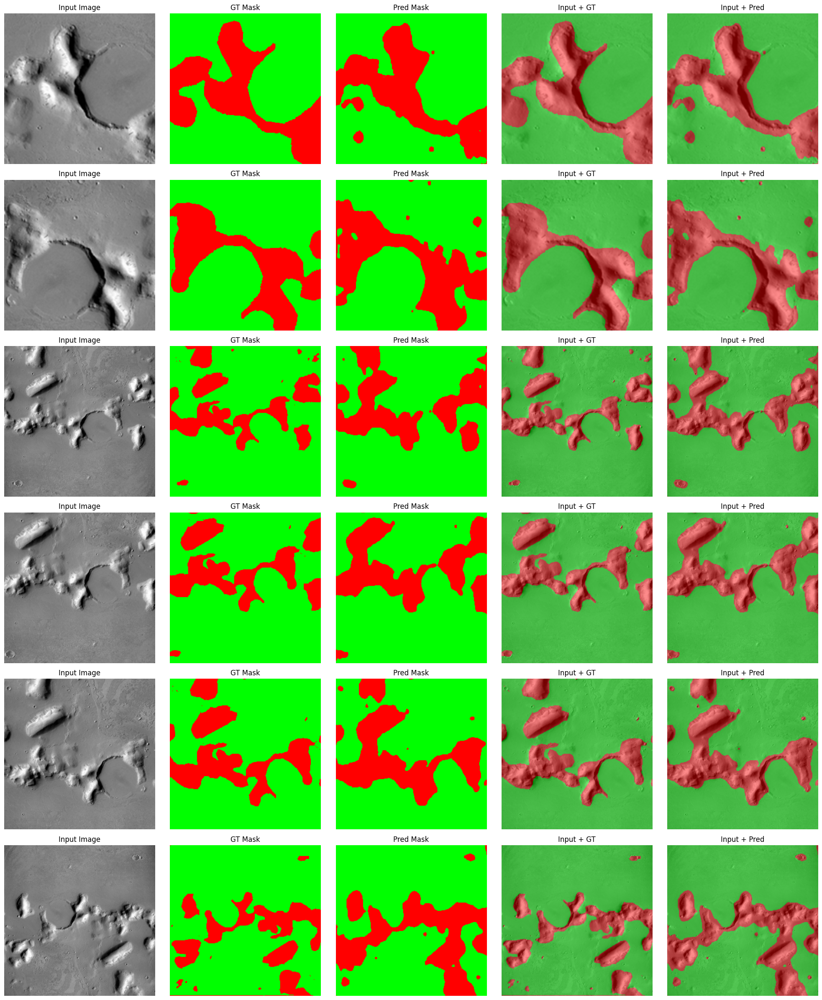

<Figure size 640x480 with 0 Axes>

In [ ]:
# ============================================================
# IMPORTS
# ============================================================
import torch
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# CONFIG
# ============================================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BEST_MODEL_PATH = "best_model_class0_iou.pth"   # <-- update if needed
NUM_ROWS = 6                                    # number of samples to show
ALPHA = 0.45                                   # overlay transparency

# ============================================================
# CLASS COLORS
# ============================================================
COLORS = {
    0: [255, 0, 0],   # Rough → Red
    1: [0, 255, 0],   # Smooth → Green
}

def mask_to_color(mask):
    """
    Convert class mask (H,W) → RGB color mask (H,W,3)
    """
    h, w = mask.shape
    color_mask = np.zeros((h, w, 3), dtype=np.uint8)
    for cls, color in COLORS.items():
        color_mask[mask == cls] = color
    return color_mask

# ============================================================
# LOAD BEST MODEL  (PyTorch 2.6 SAFE)
# ============================================================
model = BinaryUNet().to(DEVICE)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False   # 🔴 REQUIRED in PyTorch 2.6+
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(
    f"✅ Loaded best model | Epoch {checkpoint['epoch']} | "
    f"Best Class-0 IoU = {checkpoint['best_val_iou_class0']:.4f}"
)

# ============================================================
# COLLECT EXACTLY NUM_ROWS SAMPLES
# ============================================================
imgs_list, gt_list, pred_list = [], [], []

with torch.no_grad():
    for images, masks in val_loader:   # 🔁 change to test_loader if needed
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        preds = torch.argmax(model(images), dim=1)

        imgs_list.append(images.cpu())
        gt_list.append(masks.cpu())
        pred_list.append(preds.cpu())

        if sum(x.shape[0] for x in imgs_list) >= NUM_ROWS:
            break

# Concatenate & trim
images = torch.cat(imgs_list, dim=0)[:NUM_ROWS]
masks  = torch.cat(gt_list, dim=0)[:NUM_ROWS]
preds  = torch.cat(pred_list, dim=0)[:NUM_ROWS]

# ============================================================
# TO NUMPY
# ============================================================
imgs_np = images.permute(0, 2, 3, 1).numpy()  # (B,H,W,3)
gt_np   = masks.numpy()                       # (B,H,W)
pred_np = preds.numpy()                       # (B,H,W)

imgs_np = np.clip(imgs_np, 0, 1)

# ============================================================
# PLOTTING
# ============================================================
fig, axes = plt.subplots(NUM_ROWS, 5, figsize=(20, 4 * NUM_ROWS))

for i in range(NUM_ROWS):
    img = imgs_np[i]
    gt_mask = gt_np[i]
    pred_mask = pred_np[i]

    gt_color = mask_to_color(gt_mask).astype(np.float32) / 255.0
    pred_color = mask_to_color(pred_mask).astype(np.float32) / 255.0

    overlay_gt = img * (1 - ALPHA) + gt_color * ALPHA
    overlay_pred = img * (1 - ALPHA) + pred_color * ALPHA

    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Input Image")

    axes[i, 1].imshow(gt_color)
    axes[i, 1].set_title("GT Mask")

    axes[i, 2].imshow(pred_color)
    axes[i, 2].set_title("Pred Mask")

    axes[i, 3].imshow(overlay_gt)
    axes[i, 3].set_title("Input + GT")

    axes[i, 4].imshow(overlay_pred)
    axes[i, 4].set_title("Input + Pred")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()
plt.savefig("/kaggle/working/igpo.png", dpi=300)

✅ Loaded best model | Epoch 47 | Best Class-0 IoU = 0.7286


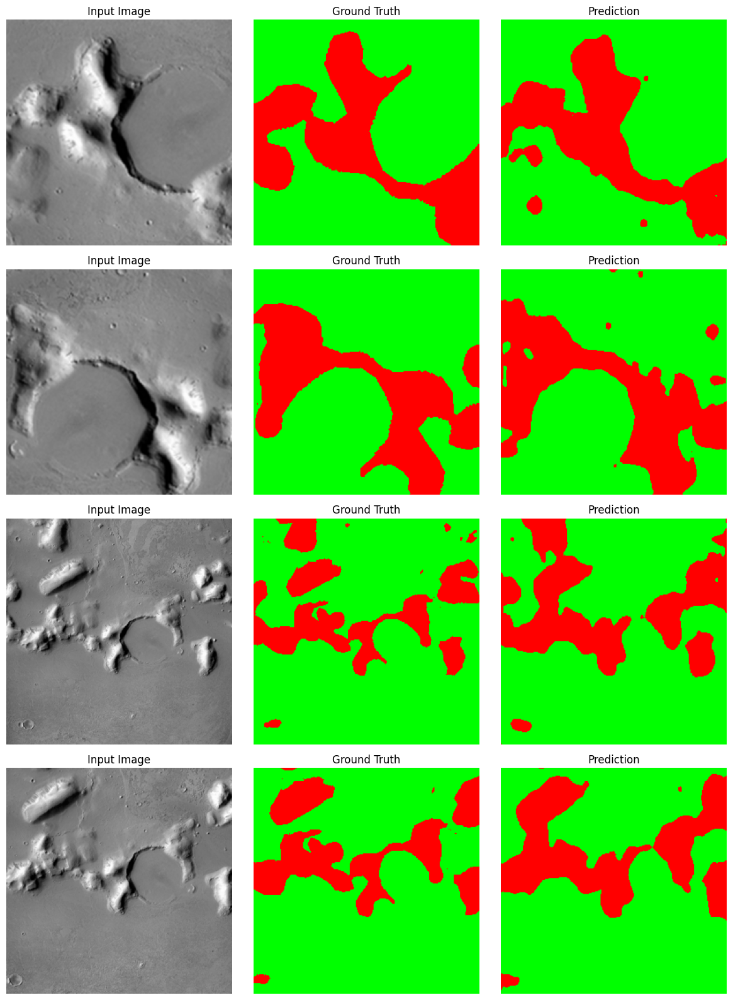

<Figure size 640x480 with 0 Axes>

In [ ]:
# ============================================================
# IMPORTS
# ============================================================
import torch
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# CONFIG
# ============================================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BEST_MODEL_PATH = "best_model_class0_iou.pth"   # <-- update if needed

# ============================================================
# CLASS COLORS
# ============================================================
COLORS = {
    0: [255, 0, 0],   # Rough → Red
    1: [0, 255, 0],   # Smooth → Green
}

def mask_to_color(mask):
    """
    Convert class mask (H,W) → RGB color mask (H,W,3)
    """
    h, w = mask.shape
    color_mask = np.zeros((h, w, 3), dtype=np.uint8)
    for cls, color in COLORS.items():
        color_mask[mask == cls] = color
    return color_mask

# ============================================================
# LOAD BEST MODEL (PyTorch 2.6 SAFE)
# ============================================================
model = BinaryUNet().to(DEVICE)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False   # 🔴 REQUIRED for PyTorch 2.6+
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(
    f"✅ Loaded best model | Epoch {checkpoint['epoch']} | "
    f"Best Class-0 IoU = {checkpoint['best_val_iou_class0']:.4f}"
)

# ============================================================
# GET ONE BATCH
# ============================================================
images, masks = next(iter(val_loader))   # 🔁 change to test_loader if needed
images = images.to(DEVICE)
masks = masks.to(DEVICE)

with torch.no_grad():
    preds = torch.argmax(model(images), dim=1)

BATCH_SIZE = images.shape[0]

# ============================================================
# PLOTTING (NO OVERLAY)
# ============================================================
fig, axes = plt.subplots(BATCH_SIZE, 3, figsize=(12, BATCH_SIZE * 4))

# Handle case when batch size = 1
if BATCH_SIZE == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(BATCH_SIZE):
    # Input Image
    img = images[i].cpu().permute(1, 2, 0).numpy()
    img = np.clip(img, 0, 1)

    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Input Image")

    # Ground Truth Mask
    gt_color = mask_to_color(masks[i].cpu().numpy())
    axes[i, 1].imshow(gt_color)
    axes[i, 1].set_title("Ground Truth")

    # Predicted Mask
    pred_color = mask_to_color(preds[i].cpu().numpy())
    axes[i, 2].imshow(pred_color)
    axes[i, 2].set_title("Prediction")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()
plt.savefig("/kaggle/working/igp.png", dpi=300)

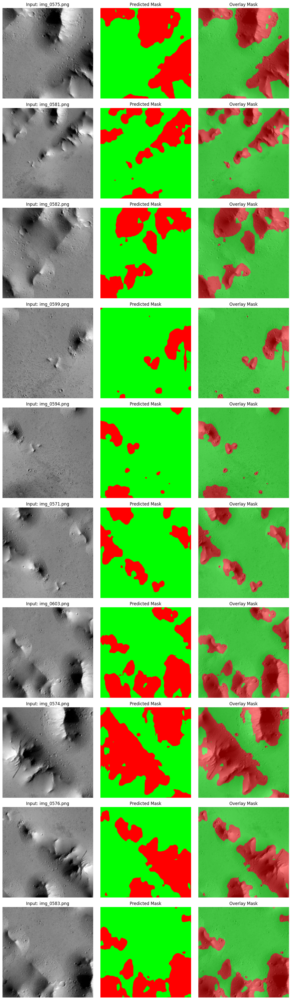

<Figure size 640x480 with 0 Axes>

In [ ]:
# Cell 11: Visualize Test Images | Predicted Mask Overlay
import os
import random
import matplotlib.pyplot as plt
import torch
import numpy as np
from PIL import Image
from torchvision import transforms

# --- 1. Setup ---
test_image_dir = r"/kaggle/input/test-sets/Test_CTX/Test_CTX"
file_names = [f for f in os.listdir(test_image_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

# --- 1a. Define color map ---
INV_COLOR_MAP = {
    0: [255, 0, 0],   # Rough → Red
    1: [0, 255, 0]    # Smooth → Green
}

def class_to_rgb(mask):
    """Convert class mask to RGB mask using color map."""
    h, w = mask.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    for cls, color in INV_COLOR_MAP.items():
        rgb[mask == cls] = color
    return rgb

def overlay_mask(image, mask_rgb, alpha=0.5):
    """Overlay the mask on top of the image."""
    return (image * (1 - alpha) + mask_rgb * alpha).astype(np.uint8)

# image transform
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])

# --- 2. Visualization function ---
def visualize_test_predictions(model, device, n_samples=4, alpha=0.5):
    model.eval()
    samples = random.sample(file_names, n_samples)

    fig, axes = plt.subplots(n_samples, 3, figsize=(12, 4*n_samples))
    for i, fname in enumerate(samples):
        # load image
        path = os.path.join(test_image_dir, fname)
        img_pil = Image.open(path).convert("RGB")
        img_resized = img_pil.resize((256, 256))
        img_tensor = transform(img_pil).unsqueeze(0).to(device)

        # forward pass
        with torch.no_grad():
            logits = model(img_tensor)
            pred = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

        # convert to RGB mask
        pred_rgb = class_to_rgb(pred)
        # overlay
        overlay = overlay_mask(np.array(img_resized), pred_rgb, alpha=alpha)

        # plot
        axes[i, 0].imshow(np.array(img_resized))
        axes[i, 0].set_title(f"Input: {fname}")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(pred_rgb)
        axes[i, 1].set_title("Predicted Mask")
        axes[i, 1].axis('off')

        axes[i, 2].imshow(overlay)
        axes[i, 2].set_title("Overlay Mask")
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()


# --- 3. Run it ---
visualize_test_predictions(model, device, n_samples=10, alpha=0.5)


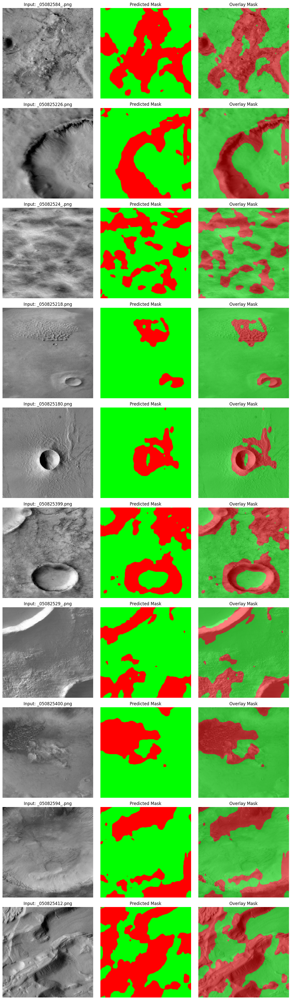

<Figure size 1200x400 with 0 Axes>

In [ ]:
# Cell 11: Visualize Test Images | Predicted Mask Overlay
import os
import random
import matplotlib.pyplot as plt
import torch
import numpy as np
from PIL import Image
from torchvision import transforms

# --- 1. Setup ---
test_image_dir = r"/kaggle/input/test-sets/Test_HiRISE/Test_HiRISE"
file_names = [f for f in os.listdir(test_image_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

# --- 1a. Define color map ---
INV_COLOR_MAP = {
    0: [255, 0, 0],   # Rough → Red
    1: [0, 255, 0]    # Smooth → Green
}

def class_to_rgb(mask):
    """Convert class mask to RGB mask using color map."""
    h, w = mask.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    for cls, color in INV_COLOR_MAP.items():
        rgb[mask == cls] = color
    return rgb

def overlay_mask(image, mask_rgb, alpha=0.5):
    """Overlay the mask on top of the image."""
    return (image * (1 - alpha) + mask_rgb * alpha).astype(np.uint8)

# image transform
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])

# --- 2. Visualization function ---
def visualize_test_predictions(model, device, n_samples=4, alpha=0.5):
    model.eval()
    samples = random.sample(file_names, n_samples)

    fig, axes = plt.subplots(n_samples, 3, figsize=(12, 4*n_samples))
    for i, fname in enumerate(samples):
        # load image
        path = os.path.join(test_image_dir, fname)
        img_pil = Image.open(path).convert("RGB")
        img_resized = img_pil.resize((256, 256))
        img_tensor = transform(img_pil).unsqueeze(0).to(device)

        # forward pass
        with torch.no_grad():
            logits = model(img_tensor)
            pred = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

        # convert to RGB mask
        pred_rgb = class_to_rgb(pred)
        # overlay
        overlay = overlay_mask(np.array(img_resized), pred_rgb, alpha=alpha)

        # plot
        axes[i, 0].imshow(np.array(img_resized))
        axes[i, 0].set_title(f"Input: {fname}")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(pred_rgb)
        axes[i, 1].set_title("Predicted Mask")
        axes[i, 1].axis('off')

        axes[i, 2].imshow(overlay)
        axes[i, 2].set_title("Overlay Mask")
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()
    plt.figure(figsize=(12,4))
    plt.savefig(f"/kaggle/working/{fname}_comparison.png", dpi=300, bbox_inches="tight")



# --- 3. Run it ---
visualize_test_predictions(model, device, n_samples=10, alpha=0.5)
